# Background files

In [ ]:
# Creating background files

# Using simulated files of a star cluster (4 dithers)
from glob import glob as gb
import os
from flo.wfiskymatch import asdf2healpix
path = '/Users/dfadda/Roman/FLO_Test/WFI_cosmosSIM_F106/'
outdir = '/Users/dfadda/Roman/FLO_Test/Test/'
files = sorted(gb(os.path.join(path,'r0003201001001001004*wfi*_cal*asdf')))
for file in files:
    asdf2healpix(file, outdir)

# Pixmatch offsets

In [ ]:
# Computing offsets
from flo.wfiskymatch import pixmatch
from glob import glob as gb
import os

outdir = '/Users/dfadda/Roman/FLO_Test/Test/'
files = sorted(gb(os.path.join(outdir,'*cal*.h5')))

object = 'simulations'
offsets = pixmatch(files, outfile=outdir+object+'_offsets', offsets=None)

In [ ]:
# Add offsets to original images - create new files
from flo.wfiskymatch import addOffset
import h5py

path = '/Users/dfadda/Roman/FLO_Test/Test/'
h5file = path + 'simulations_offsets.h5'
with h5py.File(h5file, 'r') as hdf5_file:
    files = hdf5_file['files'][:]
    offsets = hdf5_file['offsets'][:]


# Create new files with added offsets
path = '/Users/dfadda/Roman/FLO_Test/WFI_cosmosSIM_F106/'
outdir = '/Users/dfadda/Roman/FLO_Test/Offset/'
for file, offset in zip(files,offsets):
    print(file.decode(), offset)
    L2 = path + file.decode() +'.asdf'
    addOffset(L2, offset=offset, outdir = outdir)

# Romancal mosaic

In [ ]:
# Association file
import romancal.associations.asn_from_list as asn_from_list
from glob import glob as gb

path = '/Users/dfadda/Roman/FLO_Test/Offset/'
input_files = gb(path+'*_off_cal.asdf')
product_name = 'mosaic_bkgmatched'

# Create the ASN JSON object
asn = asn_from_list.asn_from_list([(i, 'science') for i in input_files], 
                                  product_name=product_name, 
                                  with_exptype=True, target='')

# Write the ASN file to disk
_, serialized = asn.dump(format='json')
with open(path+'mosaic_bkgmatched_asn.json', 'w') as f:
    f.write(serialized)

In [ ]:
# Mosaic without computing new offsets
from romancal.pipeline import MosaicPipeline

path = '/Users/dfadda/Roman/FLO_Test/Offset/'
steps = {'outlier_detection':{'skip':True},
         'skymatch':{'skip':True},
         'resample':{'resample_on_skycell':False},
        'source_catalog':{'skip':True}}

result = MosaicPipeline.call(path+'mosaic_bkgmatched_asn.json', 
                             save_results=True, resample_on_skycell=False,
                             steps=steps)

Pixel scale  1.0  pixels


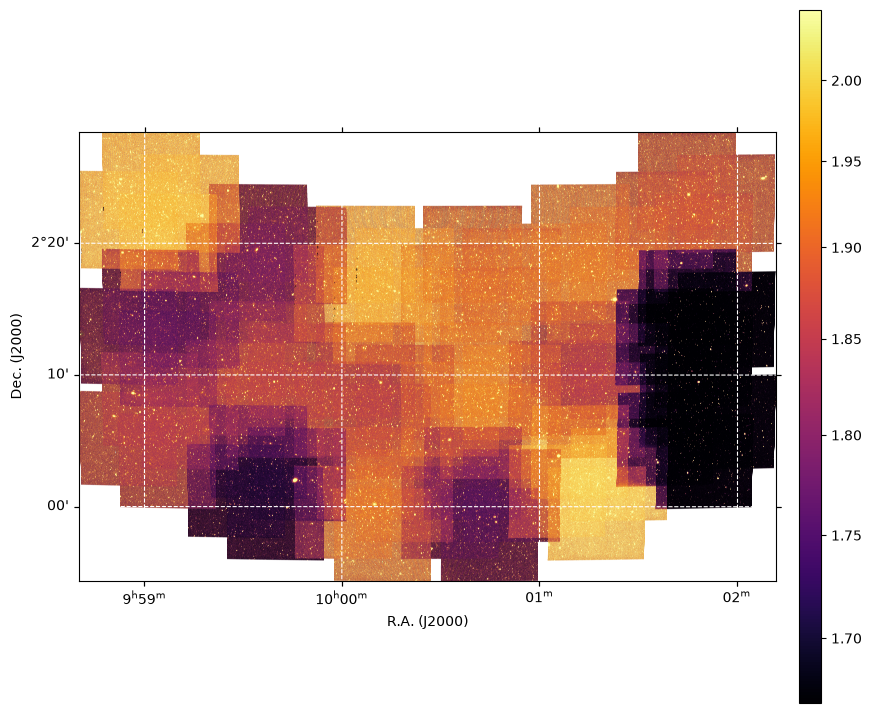

In [9]:
# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
import numpy as np

filename = 'mosaic_bkgmatched_coadd.asdf'

with rdm.open(filename) as dm:
    wcs = dm.meta.wcs
    meta = dm.meta
    data = dm.data.copy()
    hdr = dm.meta.wcs.to_fits()[0]
    print('Pixel scale ', dm.meta.resample['pixel_scale_ratio'],' pixels')

from astropy.wcs import WCS
wcs = WCS(hdr)

norm = visualization.ImageNormalize(data,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(data, norm=norm, origin='lower',cmap='inferno')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

# Flip RA axis:

xlim = ax.get_xlim()
ax.set_xlim(xlim[1], xlim[0])

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)

plt.show()

# Astropy mosaic

In [ ]:
# Code to obtain a mosaic with astropy::reproject

def makeMosaic(files, outfile='mosaic_reproject.fits'):
    from reproject.mosaicking import reproject_and_coadd
    from reproject.mosaicking import find_optimal_celestial_wcs
    from astropy.io import fits
    import roman_datamodels as rd
    import os
    import numpy as np
    from astropy.wcs import WCS

    elist=[]
    for file in files:
        print('.',end='')
        with rd.open(file) as dm:
            array = dm.data.copy()
            header = dm.meta.wcs.to_fits()[0]
            wcs = WCS(header)
            elist.append((array,wcs))
    print('\n All files read')
    
    # Extent of the coaddition
    wcs_out, shape_out = find_optimal_celestial_wcs(elist)
    print('Found optimal shape')
    # Mosaic
    earray, footprint = reproject_and_coadd(elist,
                                            wcs_out, shape_out=shape_out,
                                            reproject_function=reproject_interp,
                                            match_background=False,
                                            blank_pixel_value=np.nan)
    print('Reproject completed')
    # Save mosaic
    fits.writeto(outfile, earray, wcs_out.to_header(), overwrite=True)
    print('File saved')

In [ ]:
# Mosaic
from glob import glob as gb

files = gb('Offset/*_cal.asdf')
makeMosaic(files, outfile='mosaic_pixmatch_reproject.fits')

Filename: mosaic_pixmatch_reproject.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      20   (30763, 19823)   float64   


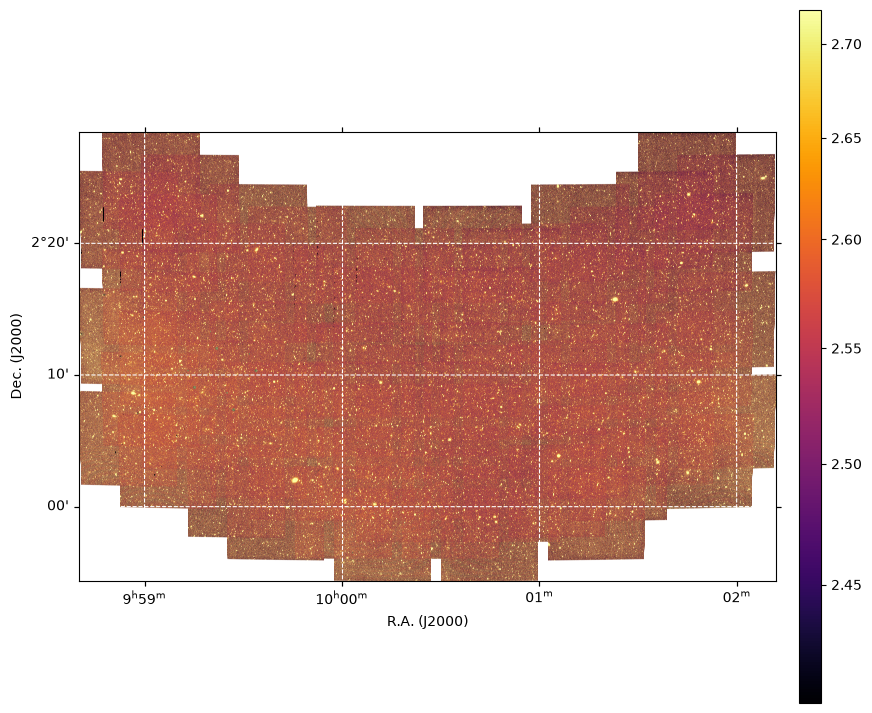

In [8]:
# Display mosaic
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy import visualization
import numpy as np

filename = 'mosaic_pixmatch_reproject.fits'

with fits.open(filename) as hdul:
    hdul.info()
    hdr = hdul[0].header
    data = hdul[0].data

from astropy.wcs import WCS
wcs = WCS(hdr)

norm = visualization.ImageNormalize(data,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(data, norm=norm, origin='lower',cmap='inferno')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

# Flip RA axis:

xlim = ax.get_xlim()
ax.set_xlim(xlim[1], xlim[0])

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)

plt.show()

........................................................................

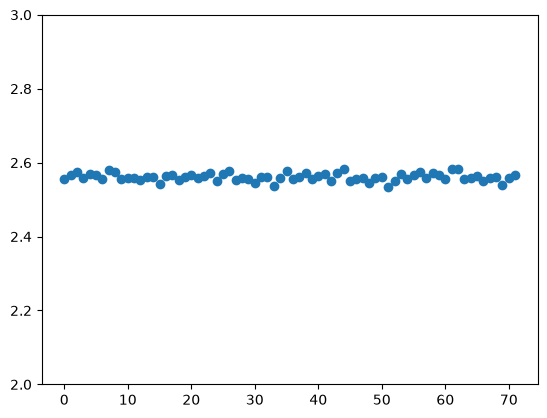

In [7]:
# Median values of offset images

from glob import glob as gb
import os
import roman_datamodels as rdm
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt


path = '/Users/dfadda/Roman/FLO_Test/Offset/'
files = sorted(gb(os.path.join(path,'r0003201001001001004*wfi*_off_cal.asdf')))
medians = []
for file in files:
    with rdm.open(file) as dm:
        med = np.nanmedian(dm.data)
        medians.append(med)
        print('.', end='')

plt.plot(medians, 'o')
plt.ylim(2,3)
plt.show()

# Save file with file names and medians
t = Table([files, medians], names=('File', 'Median'))
t.write('medianovalues.ecsv', overwrite=True)